# Assignment 7 — Learning Agent for Target Temperature

**Objective:** Build a simple learning agent that learns to maintain a target temperature.

The agent controls a room using three actions: **Heat, Cool, and Keep**. Instead of using a fixed rule for every situation, the agent learns which action gives better rewards.

## Idea of the simulation

The room has a target temperature of **22°C**.

At every time step:

1. The agent observes the current temperature.
2. It converts the temperature into a simple state such as **Cold, Comfortable, or Hot**.
3. It chooses an action: Heat, Keep, or Cool.
4. The room temperature changes because of the action and a small outside-temperature effect.
5. The agent receives a reward. Temperatures closer to 22°C get higher rewards.
6. The agent updates its knowledge and gradually learns better actions.

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

# Make the first run reproducible
random.seed(42)
np.random.seed(42)

## Step 1 — Define the environment

The room temperature can change from one step to the next. The outside temperature also affects the room slightly, making the task less predictable.

In [ ]:
TARGET_TEMP = 22.0
MIN_TEMP = 15.0
MAX_TEMP = 30.0

actions = ["Heat", "Keep", "Cool"]
action_change = {
    "Heat": 1.0,
    "Keep": 0.0,
    "Cool": -1.0
}

def get_state(temperature):
    # Convert the exact temperature into a simple learning state
    if temperature < 21:
        return "Cold"
    elif temperature > 23:
        return "Hot"
    else:
        return "Comfortable"

def get_reward(temperature):
    # Higher reward means the temperature is closer to the target
    error = abs(TARGET_TEMP - temperature)
    return 10 - error


## Step 2 — Create the learning agent

The agent uses a small **Q-table**. Each row represents a temperature state and each column represents an action.

The Q-value tells the agent how useful an action has been in a particular state.

In [ ]:
states = ["Cold", "Comfortable", "Hot"]

q_table = {
    state: {action: 0.0 for action in actions}
    for state in states
}

learning_rate = 0.2
discount_factor = 0.8
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.97

def choose_action(state, epsilon):
    # Exploration: sometimes try a random action
    if random.random() < epsilon:
        return random.choice(actions)

    # Exploitation: choose the action with the highest learned value
    values = q_table[state]
    best_value = max(values.values())
    best_actions = [action for action in actions if values[action] == best_value]
    return random.choice(best_actions)


## Step 3 — Simulate the room

The `update_temperature()` function models the room. The action changes the temperature, while the outside temperature creates a small disturbance.

In [ ]:
def update_temperature(temperature, action, outside_temperature=18):
    # Effect of the agent's action
    new_temperature = temperature + action_change[action]

    # The room slowly moves toward the outside temperature
    new_temperature += 0.08 * (outside_temperature - new_temperature)

    # Small random disturbance
    new_temperature += random.uniform(-0.15, 0.15)

    return max(MIN_TEMP, min(MAX_TEMP, new_temperature))


## Step 4 — Train the learning agent

During training, the agent tries different actions. The Q-table is updated after every action, so the agent gradually learns which actions are useful.

In [ ]:
def train_agent(episodes=100, steps_per_episode=40):
    global q_table

    # Start with no prior knowledge for a fresh training run
    q_table = {
        state: {action: 0.0 for action in actions}
        for state in states
    }

    epsilon = 1.0
    episode_rewards = []

    for episode in range(episodes):
        temperature = random.uniform(18, 27)
        total_reward = 0

        for step in range(steps_per_episode):
            state = get_state(temperature)
            action = choose_action(state, epsilon)

            new_temperature = update_temperature(temperature, action)
            reward = get_reward(new_temperature)
            next_state = get_state(new_temperature)

            old_value = q_table[state][action]
            best_next_value = max(q_table[next_state].values())

            # Q-learning update
            new_value = old_value + learning_rate * (
                reward + discount_factor * best_next_value - old_value
            )

            q_table[state][action] = new_value
            temperature = new_temperature
            total_reward += reward

        episode_rewards.append(total_reward)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    return episode_rewards, epsilon


episode_rewards, final_epsilon = train_agent()

print("Training completed.")
print("Final exploration rate:", round(final_epsilon, 3))

Training completed.
Final exploration rate: 0.05


## Step 5 — See what the agent learned

The Q-table is the agent's learned knowledge. The largest value in each row represents the action the agent currently prefers.

In [ ]:
print("Learned Q-Table")
print("=" * 55)
print(f"{'State':<15}{'Heat':>12}{'Keep':>12}{'Cool':>12}{'Best Action':>15}")
print("-" * 66)

for state in states:
    heat = q_table[state]["Heat"]
    keep = q_table[state]["Keep"]
    cool = q_table[state]["Cool"]
    best_action = max(q_table[state], key=q_table[state].get)

    print(f"{state:<15}{heat:>12.2f}{keep:>12.2f}{cool:>12.2f}{best_action:>15}")

Learned Q-Table
State                  Heat        Keep        Cool    Best Action
------------------------------------------------------------------
Cold                  46.66       45.09       44.23           Heat
Comfortable           46.51       46.37       46.08           Heat
Hot                   45.64       46.32       46.98           Cool


## Step 6 — Visualize learning progress

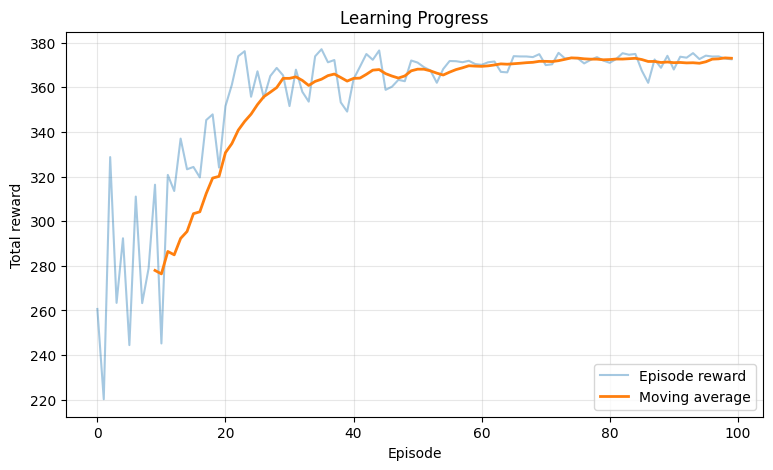

In [ ]:
# Smooth the rewards to make the learning trend easier to see
window = 10
moving_average = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(9, 5))
plt.plot(episode_rewards, alpha=0.4, label="Episode reward")
plt.plot(
    range(window - 1, len(episode_rewards)),
    moving_average,
    linewidth=2,
    label="Moving average"
)
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("Learning Progress")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Step 7 — Visualize the learned Q-values

This heatmap shows which actions have higher learned values in each temperature state.

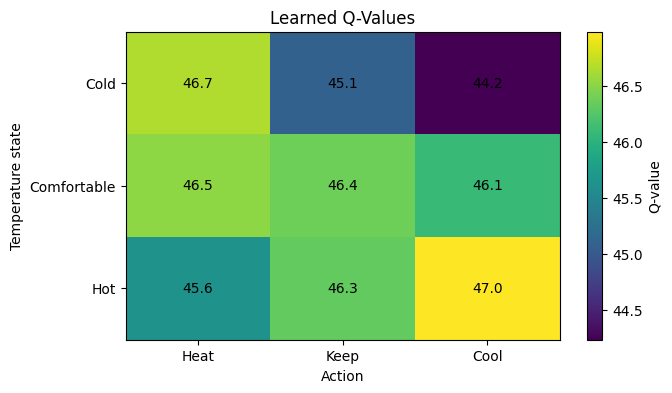

In [ ]:
q_values = np.array([
    [q_table[state][action] for action in actions]
    for state in states
])

plt.figure(figsize=(7, 4))
plt.imshow(q_values, aspect="auto")
plt.xticks(range(len(actions)), actions)
plt.yticks(range(len(states)), states)
plt.xlabel("Action")
plt.ylabel("Temperature state")
plt.title("Learned Q-Values")
plt.colorbar(label="Q-value")

for i in range(len(states)):
    for j in range(len(actions)):
        plt.text(j, i, f"{q_values[i, j]:.1f}", ha="center", va="center")

plt.show()

## Step 8 — Test the trained agent

Now the agent is tested without exploration. It uses what it learned instead of randomly trying actions.

In [ ]:
def test_agent(start_temperature=27, steps=40):
    temperature = start_temperature
    temperatures = [temperature]
    chosen_actions = []
    rewards = []

    for step in range(steps):
        state = get_state(temperature)
        action = choose_action(state, 0.0)

        temperature = update_temperature(temperature, action)
        reward = get_reward(temperature)

        chosen_actions.append(action)
        temperatures.append(temperature)
        rewards.append(reward)

    return temperatures, chosen_actions, rewards


temperatures, chosen_actions, rewards = test_agent()

print("Testing completed.")
print("Starting temperature:", temperatures[0], "°C")
print("Final temperature:", round(temperatures[-1], 2), "°C")
print("Final reward:", round(rewards[-1], 2))

Testing completed.
Starting temperature: 27 °C
Final temperature: 22.94 °C
Final reward: 9.06


## Step 9 — Temperature control graph

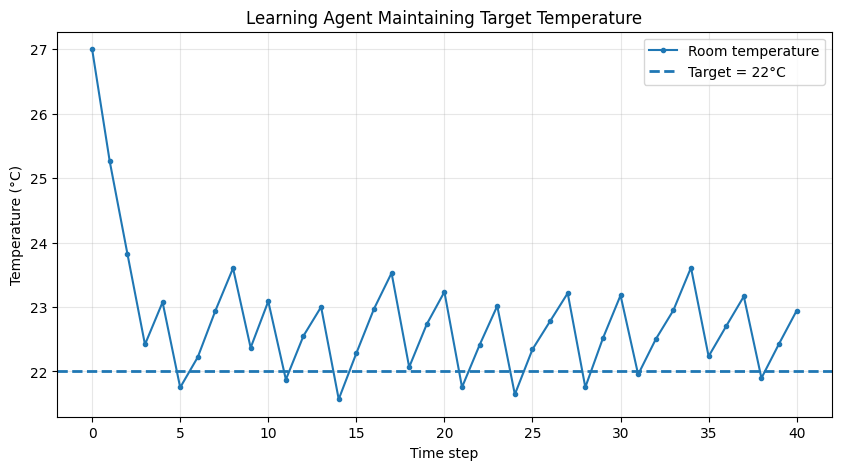

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(temperatures, marker="o", markersize=3, label="Room temperature")
plt.axhline(TARGET_TEMP, linestyle="--", linewidth=2, label="Target = 22°C")
plt.xlabel("Time step")
plt.ylabel("Temperature (°C)")
plt.title("Learning Agent Maintaining Target Temperature")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Step 10 — Show the agent's actions

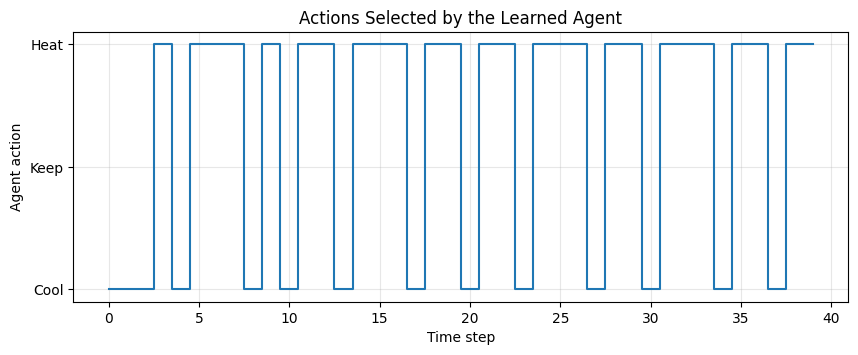

In [ ]:
action_numbers = {
    "Cool": -1,
    "Keep": 0,
    "Heat": 1
}

action_values = [action_numbers[action] for action in chosen_actions]

plt.figure(figsize=(10, 3.5))
plt.step(range(len(chosen_actions)), action_values, where="mid")
plt.yticks([-1, 0, 1], ["Cool", "Keep", "Heat"])
plt.xlabel("Time step")
plt.ylabel("Agent action")
plt.title("Actions Selected by the Learned Agent")
plt.grid(True, alpha=0.3)
plt.show()

## Step 11 — Animated temperature control

This animation shows the room temperature changing while the trained agent chooses an action at every step.

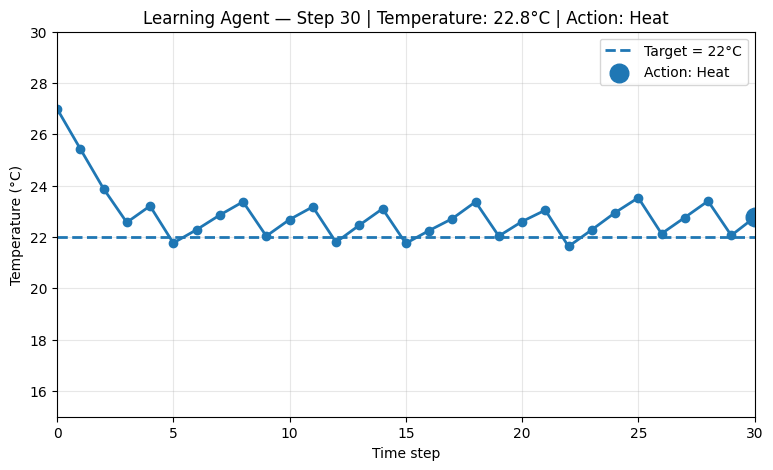

In [ ]:
# Create a shorter fresh run for the animation
animation_temperatures, animation_actions, _ = test_agent(
    start_temperature=27,
    steps=30
)

for step in range(1, len(animation_temperatures)):
    clear_output(wait=True)

    current_temp = animation_temperatures[step]
    current_action = animation_actions[step - 1]

    plt.figure(figsize=(9, 5))
    plt.plot(
        range(step + 1),
        animation_temperatures[:step + 1],
        marker="o",
        linewidth=2
    )
    plt.axhline(TARGET_TEMP, linestyle="--", linewidth=2, label="Target = 22°C")
    plt.scatter(step, current_temp, s=180, label=f"Action: {current_action}")

    plt.xlim(0, len(animation_temperatures) - 1)
    plt.ylim(MIN_TEMP, MAX_TEMP)
    plt.xlabel("Time step")
    plt.ylabel("Temperature (°C)")
    plt.title(
        f"Learning Agent — Step {step} | "
        f"Temperature: {current_temp:.1f}°C | Action: {current_action}"
    )
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    time.sleep(0.25)

clear_output(wait=True)
print("Animation completed.")
print(f"Final temperature: {animation_temperatures[-1]:.2f}°C")

## Final summary

The agent starts without knowing which action is best. Through repeated interaction with the environment, it updates its Q-table using rewards. After training, it uses the learned values to choose actions that keep the room temperature close to the target.

In [ ]:
print("Learning Agent — Final Result")
print("=" * 35)
print("Target temperature:", TARGET_TEMP, "°C")
print("Starting test temperature:", temperatures[0], "°C")
print("Final test temperature:", round(temperatures[-1], 2), "°C")
print("Final error:", round(abs(TARGET_TEMP - temperatures[-1]), 2), "°C")
print("Training episodes:", len(episode_rewards))

Learning Agent — Final Result
Target temperature: 22.0 °C
Starting test temperature: 27 °C
Final test temperature: 22.94 °C
Final error: 0.94 °C
Training episodes: 100
